# Hyperparameter tuning

Hyperparameter là thiết lập ta chọn trước khi huấn luyện, ví dụ số láng giềng $k$ của kNN. Thử vài giá trị rồi giữ giá trị cho điểm cao nhất nghe đơn giản, nhưng dễ sai ở hai chỗ: đổi nhiều thứ cùng lúc thì không biết điểm tăng nhờ đâu, và chọn theo tập test thì điểm test không còn ý nghĩa. Bài này học grid search và random search trên cross-validation, giữ nguyên cách chia và metric, và chỉ chấm test một lần sau khi đã chọn xong.

> **Mục tiêu**
>
> - Phân biệt tham số model học được với hyperparameter.
> - Tính số lần huấn luyện của một lưới thử.
> - Dùng GridSearchCV và RandomizedSearchCV với Pipeline.
> - Chấm test một lần sau khi đã chọn xong.

## Cái gì được học, cái gì được lựa chọn?

Trong linear regression, các trọng số do thuật toán học từ train: đó là **parameter** (tham số). Trong kNN, số hàng xóm $k$ do ta đặt trước khi fit: đó là **hyperparameter**. Độ sâu của cây quyết định, mức phạt regularization, learning rate, ngưỡng phân loại cũng là hyperparameter: ta chọn chúng bằng cách thử và so điểm validation.

Một hyperparameter không nhất thiết nằm trong lời gọi constructor. Chọn feature, chọn kiểu imputation hay cách biến target cũng là những quyết định dựa trên validation. Tập test phải đứng ngoài **toàn quy trình quyết định**, không chỉ đứng ngoài một dòng fit cuối.

Ta gọi phần dữ liệu dùng để phát triển phương án là development set (dev), gồm các mẫu cho train/validation hoặc CV. Trước khi tuning, tách test ngoài. Bên trong dev, splitter của CV sẽ tạo train và validation riêng cho từng fold.

**Hỏi nhanh.** Ngưỡng phân lớp được chọn sao cho F1 trên validation cao nhất. Ngưỡng ấy có tính là một phần của phương án cần đánh giá không?

- A. Không, vì nó không được học như trọng số
- B. Có, vì nó được chọn bằng điểm validation
- C. Không, chỉ trọng số của mô hình mới cần đánh giá
- D. Chỉ khi ngưỡng khác mức mặc định 0.5

<details><summary>Đáp án</summary>

B. Có, vì nó được chọn bằng điểm validation

Mọi thứ được chọn bằng cách nhìn điểm validation đều là một phần của phương án, dù đó là tham số, feature hay ngưỡng. Tập test độc lập phải đứng ngoài cả quy tắc ra nhãn, chứ không chỉ đứng ngoài việc fit trọng số.

</details>

## Grid search là một bảng tổ hợp

Grid search thử mọi tổ hợp trong những danh sách cho trước. Nếu thử $k\in\{3,9,21\}$ và `weights` gồm uniform, distance, ta có $3\cdot2=6$ cấu hình. Uniform lấy phiếu của các hàng xóm với trọng số bằng nhau; distance cho điểm gần hơn trọng số lớn hơn. Cơ chế kNN được học kỹ ở bài 2.4; ở đây chỉ cần biết hai lựa chọn là hai giả thuyết để kiểm.

Với ba fold, sáu cấu hình cần $6 \cdot 3 = 18$ lần fit. Nếu đặt `refit=True`, chọn xong còn một lần fit nữa trên toàn bộ dev, tổng 19. Công thức chung:

$$\text{số lần fit} = \text{số tổ hợp} \times \text{số fold} \; (+1 \text{ nếu refit}).$$

Ví dụ 3 giá trị `C` và 2 kernel với `cv=5` cần 30 lần fit, chưa kể refit. Thời gian cũng tính như vậy: mỗi lần học mất 1 giờ, mỗi tổ hợp 4 fold, thì 100 giờ chỉ đủ thử 25 tổ hợp.



Không thử một grid khổng lồ ngay đầu. Giữ một baseline, chọn vài tham số có ý nghĩa, rồi mở rộng vùng có bằng chứng. Nếu lựa chọn tốt nhất nằm ở biên danh sách $k$, có thể cần xem giá trị gần đó hoặc ngoài biên, nhưng không tự kết luận rằng càng xa càng tốt.

## Chuẩn bị dữ liệu và cố định phép đánh giá

Ta sinh 240 mẫu classification giả, sáu feature; lớp 1 ít hơn lớp 0. Ví dụ này mô phỏng mẫu độc lập, nên dùng stratified split và StratifiedKFold. Nếu đề thật có group hoặc thời gian, thay splitter theo bài 1.3, không giữ random chỉ vì tiện.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(
    n_samples=240, n_features=6, n_informative=3, n_redundant=1,
    weights=[0.65, 0.35], flip_y=0.08, random_state=17,
)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=17
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=17)
pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier()),
])
print('Dev/test shape:', X_dev.shape, X_test.shape)
print('Số lớp 1 dev/test:', int(y_dev.sum()), int(y_test.sum()))

Dev/test shape: (192, 6) (48, 6)
Số lớp 1 dev/test: 73 18


Scaler nằm trong Pipeline để mỗi fold học thang đo từ train của nó. Trong kNN, khoảng cách phụ thuộc đơn vị feature nên thang đo là một phần của phương án. `random_state=17` giữ phép chia tái lập được; nó không biến một split tùy ý thành split đúng.

Ta chọn F1 của lớp 1 để so cấu hình. Nhãn được tạo bằng `predict` của classifier, giữ cùng quy tắc cho mọi ứng viên; bài này chưa tuning threshold riêng. Nếu muốn thêm threshold vào quy trình, phải chọn nó bằng prediction validation/OOF phù hợp, không chấm thử trên test.

**Hỏi nhanh.** Grid search thử bốn giá trị của tham số A và ba giá trị của tham số B, dùng cross-validation năm fold, rồi refit một lần. Tổng cộng phải fit bao nhiêu lần?

- A. 12
- B. 17
- C. 60
- D. 61

<details><summary>Đáp án</summary>

D. 61

Có $4 \cdot 3 = 12$ cấu hình, mỗi cấu hình chạy năm fold, rồi thêm một lần fit cuối: $12 \cdot 5 + 1 = 61$. Ra 17 là cộng nhầm $12 + 5$. Ra 60 là quên lần refit.

</details>

## Chạy grid và đọc bảng log

Tên tham số đi qua Pipeline có dạng `tên_bước__tên_tham_số`: `knn__n_neighbors` là tham số của bước `knn`. `return_train_score=True` lưu điểm train để giúp chẩn đoán, nhưng quyết định thắng dựa trên validation CV.

In [ ]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    pipeline,
    param_grid={
        'knn__n_neighbors': [3, 9, 21],
        'knn__weights': ['uniform', 'distance'],
    },
    scoring='f1', cv=cv, n_jobs=1, refit=True,
    return_train_score=True, error_score='raise',
)
grid.fit(X_dev, y_dev)
log = pd.DataFrame(grid.cv_results_)
columns = ['param_knn__n_neighbors', 'param_knn__weights', 'mean_train_score', 'mean_test_score']
print(log[columns].round(3).to_string(index=False))
print('Grid chọn:', grid.best_params_)
print(f'Best CV F1={grid.best_score_:.3f}')

 param_knn__n_neighbors param_knn__weights  mean_train_score  mean_test_score
                      3            uniform             0.801            0.649
                      3           distance             1.000            0.649
                      9            uniform             0.702            0.677
                      9           distance             1.000            0.685
                     21            uniform             0.615            0.614
                     21           distance             1.000            0.661
Grid chọn: {'knn__n_neighbors': 9, 'knn__weights': 'distance'}
Best CV F1=0.685




Hình vẽ lại đúng bảng trên. Nét đứt màu cam nằm sát 1 ở mọi k; nét liền cho thấy CV tăng từ k=3 lên k=9 rồi giảm, nên vùng đáng thử thêm nằm quanh 9 chứ không ở biên.

Trong `cv_results_`, tên `mean_test_score` chỉ validation của CV, **không phải** test ngoài mà ta giữ lại. Đây là một chỗ dễ nhầm từ vựng. `best_score_` là trung bình fold của ứng viên thắng trong vùng đã thử, không phải đánh giá trung lập về mọi dữ liệu mới.

Đọc bảng trước khi mở rộng search. Train cao nhưng CV thấp gợi ý mô hình bám train quá sát; kNN distance có thể khớp train rất mạnh vì điểm chính nó có khoảng cách 0. Nếu cả hai thấp, xem feature, nhiễu và khả năng model. Nếu model tốt chỉ ở một fold, đọc lỗi của fold ấy và số mẫu lớp 1.

Muốn xem từng fold, đọc các cột `split0_test_score`, `split1_test_score`, `split2_test_score` của cùng một cấu hình.

**Hỏi nhanh.** Trong log của grid search, mọi dòng `weights=distance` đều có `mean_train_score` bằng 1.000. Vì sao vậy?

- A. Vì `distance` overfit nặng nhất, nên phải loại ngay
- B. Vì scaler đã lấy thông tin của validation trong từng fold
- C. Vì mỗi điểm train là hàng xóm cách chính nó một khoảng 0
- D. Vì `distance` là tốt nhất, điểm train cao nhất

<details><summary>Đáp án</summary>

C. Vì mỗi điểm train là hàng xóm cách chính nó một khoảng 0

Khi đoán trên chính train, điểm cần đoán có sẵn trong dữ liệu, cách chính nó một khoảng 0. Với `weights="distance"`, điểm ấy chiếm toàn bộ trọng số, nên nhãn đoán ra là nhãn của chính nó. Điểm train 1.000 là do cơ chế, không tự nói lên overfit hay tốt. Ta vẫn chọn theo cột điểm CV, nơi $k = 9$ với `distance` cao nhất, 0.685.

</details>

## Random search và ngân sách

Random search lấy một số cấu hình từ vùng cho trước, thay vì duyệt mọi tổ hợp. Nó có ích khi số chiều tham số lớn hoặc có vài tham số quan trọng hơn những tham số khác. Với một grid rất nhỏ thì duyệt hết cũng hợp lý; không có thuật toán search luôn thắng.



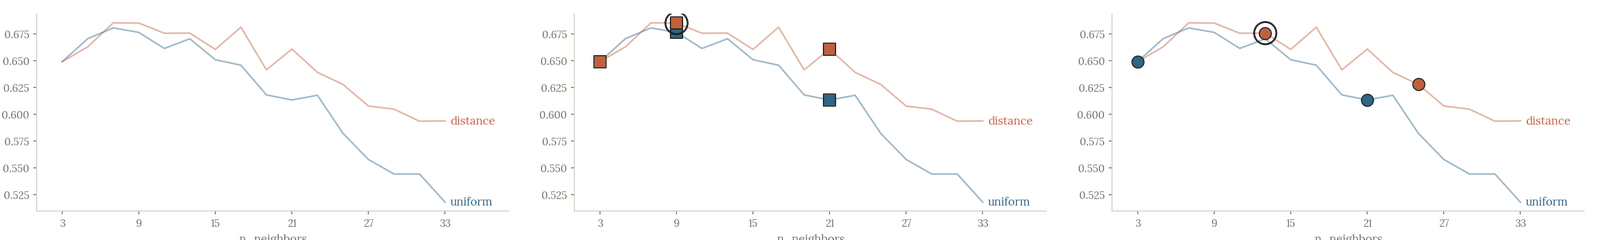

Code sau thử bốn tổ hợp từ 16 giá trị $k$ lẻ và hai kiểu weights, vẫn trên **cùng CV** và metric F1. Không tăng số worker để chiếm toàn bộ CPU trong ví dụ nhỏ.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    pipeline,
    param_distributions={
        'knn__n_neighbors': list(range(3, 34, 2)),
        'knn__weights': ['uniform', 'distance'],
    },
    n_iter=4, scoring='f1', cv=cv, random_state=17,
    n_jobs=1, refit=True, return_train_score=True, error_score='raise',
)
random_search.fit(X_dev, y_dev)
print('Số ứng viên grid/random:', len(grid.cv_results_['params']), len(random_search.cv_results_['params']))
print('Random chọn:', random_search.best_params_)
print(f'Random best CV F1={random_search.best_score_:.3f}')

Số ứng viên grid/random: 6 4
Random chọn: {'knn__weights': 'distance', 'knn__n_neighbors': 13}
Random best CV F1=0.676


Random search lấy giá trị ngẫu nhiên trong một vùng, nên cách đặt vùng rất quan trọng. Với tham số trải qua nhiều bậc độ lớn, như mức phạt hay learning rate, nên lấy theo **thang log**:

- Lấy đều trong $[0.01, 1]$ thì gần hết các điểm rơi vào $[0.1, 1]$, vùng $[0.01, 0.1]$ hầu như không được thử.
- Lấy $10^u$ với $u$ đều trong $[-2, 0]$ thì mỗi bậc độ lớn được thử như nhau.
- Tham số sát 1, như $\beta_1$ của Adam (bài 3.5), thì lấy theo log của $1 - \beta_1$: lấy đều trong $[0.9, 0.999]$ chỉ có khoảng 9% khả năng rơi vào $(0.99, 0.999)$.

Sau hai lượt, lựa chọn giữa grid và random cũng là một quyết định trên CV. Ta chốt phương án có CV F1 cao hơn; nếu bằng nhau, quy ước chọn grid. Không đọc test để đổi quy tắc hòa.

**Hỏi nhanh.** Tuning xong, có thể báo `GridSearchCV.best_score_` như một điểm test độc lập không?

- A. Được, vì cột trong log có tên là `mean_test_score`
- B. Được, nếu cross-validation dùng từ năm fold trở lên
- C. Không, vì đó là điểm CV đã dùng để chọn
- D. Không, vì đó là điểm train của ứng viên thắng

<details><summary>Đáp án</summary>

C. Không, vì đó là điểm CV đã dùng để chọn

Ứng viên thắng được chọn chính vì điểm này, nên con số thường quá lạc quan. Khi nhiều ứng viên ngang nhau, người thắng hay là người gặp may trên các fold. Muốn đánh giá sau khi chọn, ta cần một tập test riêng hoặc nested CV. Điểm train thì nằm ở cột `mean_train_score`.

</details>

## Chốt phương án và mở test một lần

Với `refit=True`, `best_estimator_` của mỗi search đã được fit lại trên toàn dev bằng cấu hình thắng của search đó. Vì vậy không cần tự fit thêm một lần với tham số mặc định. Ta chọn giữa hai kết quả bằng CV rồi mới gọi predict trên test.

In [ ]:
from sklearn.metrics import f1_score, confusion_matrix

if grid.best_score_ >= random_search.best_score_:
    chosen_search, chosen_name = grid, 'grid'
else:
    chosen_search, chosen_name = random_search, 'random'
final_model = chosen_search.best_estimator_
test_prediction = final_model.predict(X_test)
print('Phương án đã chốt:', chosen_name, chosen_search.best_params_)
print(f'Test F1={f1_score(y_test, test_prediction):.3f}')
print(confusion_matrix(y_test, test_prediction, labels=[0, 1]))

Phương án đã chốt: grid {'knn__n_neighbors': 9, 'knn__weights': 'distance'}
Test F1=0.727
[[27  3]
 [ 6 12]]


Đọc cả confusion matrix để thấy F1 là tổng hợp của loại lỗi nào. Test chỉ có 48 mẫu, nên score còn nhiễu. Sau khi đã nhìn kết quả, nếu cần sửa model, tập này trở thành dữ liệu phát triển cho vòng sau; muốn báo đánh giá độc lập mới thì cần dữ liệu chưa tham gia quyết định.

Không có test ngoài mà cần đánh giá **quy trình tuning** thì dùng nested CV: vòng trong chọn cấu hình, vòng ngoài giữ mẫu ra khỏi toàn bộ việc chọn rồi chấm. Chỉ báo điểm CV tốt nhất của vòng trong thường lạc quan do đã chọn người thắng từ nhiều ứng viên. Cái giá là số fit nhân lên theo số outer fold.



## Ví dụ tính tay và quyết định thử gì tiếp

Ba fold F1 của A là $(0.7, 0.8, 0.9)$, của B là $(0.8, 0.8, 0.8)$. Cả hai có trung bình 0.8. Chưa thể nói B chắc chắn tốt hơn chỉ vì các số đều nhau; khi hòa, chọn theo quy tắc đặt từ trước, như model rẻ hơn hay đơn giản hơn.

Grid của bài có 19 fit kể cả refit; random search có $4\cdot3+1=13$ fit, tổng 32. Một vòng search mới phải có câu hỏi: thử $k$ lớn hơn để giảm khoảng cách train–CV? Thử feature mới để sửa nhóm lỗi? Hay giữ model vì cải thiện quá nhỏ so với dao động? Mỗi lần đổi một ý chính sẽ dễ giải thích hơn.

**Hỏi nhanh.** Thấy F1 trên test thấp, cả đội chỉnh tiếp mô hình, rồi báo điểm trên chính test ấy như thể chưa từng dùng. Làm vậy có được không?

- A. Không, vì các lần chỉnh sau đã dựa vào thông tin của test
- B. Được, nếu chỉ đổi vài tham số
- C. Được, miễn là không fit mô hình trên test
- D. Không, vì phải bỏ hẳn test, không được học gì từ nó

<details><summary>Đáp án</summary>

A. Không, vì các lần chỉnh sau đã dựa vào thông tin của test

Vẫn được rút kinh nghiệm từ lỗi trên test. Nhưng từ lúc nhìn điểm test để chỉnh, test đã thành dữ liệu dùng để phát triển. Muốn báo một con số độc lập, ta cần dữ liệu chưa tham gia quyết định nào.

</details>

## Khi đi thi

- **Nộp sớm một baseline đúng định dạng**, để lúc nào cũng có một bài hợp lệ.
- **Mỗi lần thử có một giả thuyết**; lưu recipe, tham số, seed và điểm validation.
- **Đếm chi phí trước khi chạy**: số ứng viên × số fold (+1 nếu refit) × thời gian một fit, so với thời gian còn lại.
- **Chọn bài cuối theo CV đúng split.** Bảng điểm công khai chỉ chấm một phần nhỏ của test; dùng nó để chọn quá nhiều lần là overfit vào chính phần ấy.
- Đọc giới hạn runtime, số lượt nộp và môi trường trong thông báo của cuộc thi.

## Tóm tắt

- Hyperparameter là thứ ta chọn bằng cách thử và so điểm validation; test phải đứng ngoài mọi lựa chọn.
- So các cấu hình trên cùng cách chia, cùng metric, cùng Pipeline.
- Grid search thử mọi tổ hợp; random search lấy ngẫu nhiên một số tổ hợp, hợp khi có nhiều tham số.
- Điểm CV tốt nhất dùng để chọn, không phải để báo; báo bằng test riêng hoặc nested CV.

## Kiểm tra cuối bài

**Câu 1.** Thử 50 giá trị `random_state` cho `train_test_split`. Accuracy trên validation dao động từ 0.70 đến 0.81, trung bình 0.74. Một bạn giữ seed cho ra 0.81 và báo 0.81 là độ chính xác có thể kỳ vọng. Sai ở đâu?

- A. Không sai, vì seed chỉ dùng để chạy lại ra cùng kết quả
- B. Không sai, vì cách chia ấy hẳn có train tiêu biểu nhất
- C. Phải báo 0.70, vì cần lấy trường hợp xấu nhất
- D. 0.81 là số lớn nhất trong 50 lần đo có nhiễu, nên quá lạc quan

<details><summary>Đáp án</summary>

D. 0.81 là số lớn nhất trong 50 lần đo có nhiễu, nên quá lạc quan

Đổi seed là đổi tập validation. Chọn seed đẹp nhất là tuning trên chính validation, nên con số thắng bị đẩy lên. Báo trung bình kèm khoảng dao động, tức 0.74, từ 0.70 đến 0.81, hoặc dùng cross-validation, mới phản ánh mức có thể kỳ vọng.

</details>

**Câu 2.** Mỗi lần train mất đúng 1 giờ, dữ liệu lớn hay nhỏ cũng vậy. Ta đánh giá bằng 4 lượt chia ngẫu nhiên, mỗi lượt lấy 25% làm validation. Grid search trên hai hyperparameter, trong đó $\omega$ có 8 giá trị. Có 100 giờ, và chỉ tính thời gian train. $\gamma$ được thử tối đa bao nhiêu giá trị?

- A. 12
- B. 3
- C. 4
- D. 25

<details><summary>Đáp án</summary>

B. 3

Mỗi cặp $(\gamma, \omega)$ cần 4 lần train, nên $4 \cdot 8 \cdot g \le 100$, tức $g \le 3.125$. Vậy tối đa là 3 giá trị. Ra 12 là quên 4 lượt chia. Ra 25 là quên 8 giá trị của $\omega$. Ra 4 là làm tròn lên. Con số 25% không ảnh hưởng, vì thời gian train không phụ thuộc cỡ dữ liệu.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q3.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=16)

</details>

**Câu 3.** Pipeline có hai bước tên `scale` và `knn`. Muốn GridSearchCV thử $k$ = 3, 5, 9 cho kNN, ta viết khóa nào trong `param_grid`?

- A. `knn__n_neighbors`
- B. `knn.n_neighbors`
- C. `n_neighbors`
- D. `scale__n_neighbors`

<details><summary>Đáp án</summary>

A. `knn__n_neighbors`

Tham số bên trong Pipeline được gọi bằng tên bước, hai dấu gạch dưới, rồi tên tham số: `knn__n_neighbors`. Dấu chấm không dùng được. Thiếu tên bước thì Pipeline không biết đó là tham số của bước nào. Còn bước `scale` thì không có `n_neighbors`.

</details>

**Câu 4.** GridSearchCV dùng `scoring="neg_mean_absolute_error"`. Hai ứng viên có `mean_test_score` là $-2.1$ (A) và $-2.8$ (B). Ứng viên nào thắng, và MAE của nó là bao nhiêu?

- A. B, MAE là 2.8
- B. A, MAE là $-2.1$
- C. B, MAE là $-2.8$
- D. A, MAE là 2.1

<details><summary>Đáp án</summary>

D. A, MAE là 2.1

scikit-learn luôn chọn điểm lớn nhất, nên với metric đo lỗi nó dùng số đối. $-2.1$ lớn hơn $-2.8$, nên A thắng, và MAE thật của A là 2.1. Đây là trung bình trên các fold validation, chưa phải điểm test.

</details>

**Câu 5.** Code chạy `X_scaled = scaler.fit_transform(X_dev)` trước, rồi mới cho GridSearchCV tìm kNN trên `X_scaled`. Sửa thế nào để ở mỗi fold, scaler chỉ học từ phần train của fold đó?

- A. Fit scaler một lần trên toàn `X_dev`, nhưng sau khi đã chia fold
- B. Cho GridSearchCV tìm trên một Pipeline gồm scaler và kNN, với `X_dev` gốc
- C. Giữ `X_scaled`, chỉ tăng số fold
- D. Fit scaler thêm một lần nữa trên phần validation của mỗi fold

<details><summary>Đáp án</summary>

B. Cho GridSearchCV tìm trên một Pipeline gồm scaler và kNN, với `X_dev` gốc

Scaler đã fit trên toàn `X_dev`, nghĩa là đã nhìn cả những hàng sẽ làm validation trong từng fold. Tăng số fold hay fit thêm lần nữa đều không xóa được điều đó. Đưa Pipeline gồm scaler và kNN vào search thì ở mỗi fold, scaler được fit lại chỉ trên phần train của fold ấy.

</details>

**Câu 6.** Cuộc thi tính bảng xếp hạng công khai trên 30% test, còn bảng cuối tính trên 70% còn lại. Một đội nộp 60 lần, lần nào cũng giữ bản có điểm công khai cao hơn. Điểm công khai tăng từ 0.712 lên 0.741, còn điểm CV ở máy của các bản ấy chỉ quanh 0.70. Điểm bảng cuối nhiều khả năng là bao nhiêu?

- A. Gần 0.70 hơn là gần 0.741
- B. Khoảng 0.741, vì hai phần test giống nhau
- C. Cao hơn 0.741, vì phần tính bảng cuối lớn hơn
- D. Không đoán được, vì bảng cuối được giữ kín

<details><summary>Đáp án</summary>

A. Gần 0.70 hơn là gần 0.741

Giữ bản tốt nhất qua 60 lần theo 30% test là chọn theo nhiễu của phần công khai, giống như chọn seed đẹp nhất. Điểm CV đứng yên cho thấy mô hình không thật sự tốt lên. Khi CV chia đúng cách mà lệch với bảng công khai, ta tin CV.

</details>

**Câu 7.** GridSearchCV đặt `refit=True`. Search xong, `best_estimator_` là gì?

- A. Bộ tham số thắng, dưới dạng dictionary
- B. Mô hình thắng, được fit lại riêng trên test
- C. Mô hình thắng, được fit lại trên toàn bộ dữ liệu dev
- D. Mô hình thắng ở fold có điểm cao nhất

<details><summary>Đáp án</summary>

C. Mô hình thắng, được fit lại trên toàn bộ dữ liệu dev

Với `refit=True`, search fit lại cấu hình thắng trên toàn bộ dữ liệu dev đã truyền vào. Vì vậy `best_estimator_` dự đoán được ngay, kèm đủ mọi bước của Pipeline, kể cả scaler. Dictionary tham số là `best_params_`. Các mô hình của từng fold không được giữ lại.

</details>

**Câu 8.** Ta muốn so grid search với random search khi cả hai có cùng ngân sách tính toán. Thiết kế thí nghiệm nào công bằng nhất?

- A. Cùng số ứng viên, mỗi cách dùng một cách chia có lợi cho nó
- B. Cùng các fold, mỗi cách chọn một metric có lợi cho nó
- C. Cùng metric, mỗi cách thử một vùng tham số riêng
- D. Chung dữ liệu, chung fold, chung metric, chung vùng thử và chung ngân sách

<details><summary>Đáp án</summary>

D. Chung dữ liệu, chung fold, chung metric, chung vùng thử và chung ngân sách

Mọi điều kiện đánh giá và vùng thử phải giống nhau thì mới so được. Nếu thời gian fit của các ứng viên khác nhau, cùng số ứng viên chưa chắc cùng chi phí. Thí nghiệm chỉ cho biết kết quả trong đúng ngân sách ấy, không chứng minh cách nào lúc nào cũng tốt hơn.

</details>

**Câu 9.** Nested CV giữ lại một fold ngoài để chấm. Trên phần train của vòng ngoài, CV vòng trong chọn được $k = 7$. Trước khi dự đoán fold ngoài, ta fit cấu hình $k = 7$ trên phần nào?

- A. Toàn bộ phần train của vòng ngoài, kể cả các phần từng làm validation ở vòng trong
- B. Chỉ fold ngoài, cho khớp với dữ liệu đang chấm
- C. Chỉ phần train của fold vòng trong có điểm cao nhất
- D. Toàn bộ dữ liệu, kể cả fold ngoài, cho đủ mẫu

<details><summary>Đáp án</summary>

A. Toàn bộ phần train của vòng ngoài, kể cả các phần từng làm validation ở vòng trong

Vòng trong chỉ có nhiệm vụ chọn cấu hình. Chọn xong, ta fit lại cấu hình ấy trên toàn bộ phần train của vòng ngoài. Fold ngoài phải đứng ngoài cả việc học lẫn việc chọn của vòng trong.

</details>

**Câu 10.** Thử $k$ = 3, 7, 15, MAE trên validation lần lượt là 4.2, 3.5 và 3.1. Giá trị thắng là $k = 15$, nằm đúng ở biên. Nếu còn ngân sách, ta nên làm gì tiếp?

- A. Kết luận $k = 15$ là tối ưu, vì nó thắng cả grid
- B. Thử thêm vài $k$ lớn hơn, với cùng cách validation
- C. Chọn $k$ bằng số mẫu train, vì MAE đang giảm đều
- D. Tính thêm các $k$ trên test để chọn vùng thử tiếp theo

<details><summary>Đáp án</summary>

B. Thử thêm vài $k$ lớn hơn, với cùng cách validation

MAE vẫn đang giảm khi chạm biên vùng thử, nên đáng thử thêm vài $k$ lớn hơn với cùng cách validation. Chưa thể kết luận $k = 15$ là tốt nhất. Còn dùng test để chọn vùng thử tiếp theo là đã dùng test để tuning.

</details>

## Đọc thêm

- [scikit-learn — Tuning hyper-parameters](https://scikit-learn.org/stable/modules/grid_search.html). Tra grid/random search, refit và cách đọc `cv_results_`.
- [scikit-learn — Nested versus non-nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html). Đọc sự khác nhau giữa chọn cấu hình và đánh giá quy trình chọn.
- Bergstra, Bengio — [Random Search for Hyper-Parameter Optimization](https://jmlr.org/papers/v13/bergstra12a.html), JMLR 2012. Đọc lập luận về ngân sách khi chỉ một số tham số chi phối kết quả; không suy ra random search luôn thắng mọi grid.